# Annealing schedule

$\renewcommand{\ket}[1]{\left|#1\right\rangle}\renewcommand{\bra}[1]{\left\langle #1\right|}\renewcommand{\braket}[2]{\left\langle #1 \middle| #2 \right\rangle}\renewcommand{\ketbra}[2]{\left|#1\right\rangle\!\left\langle #2\right|}$
This notebook shows how to derive a valid annealing schedule for our instances.

Given a desired target temperature $\bar \beta$, we need to determine a schedule of inverse temperatures $0 = \beta_0 < \beta_1 < \ldots < \beta_L = \bar \beta$ satisfying the condition
$$\left(\sum_x \sqrt{\pi_{\beta_j}(x) \, \pi_{\beta_{j+1}}(x)} \right)^2\ge 1/e.$$

This can be obtained starting from $\beta_0 = 0$ and incrementing each step by $\Delta \beta(n, \beta)$ where 
$$\Delta\beta(n, \beta) = \frac{ 2 }{ \sqrt{ \operatorname{Var}_{\pi_{\beta+\Delta\beta/2}}(H) } }.$$

## Import

In [39]:
import sys

if ".." not in sys.path:
    sys.path.append("..")

import math
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import sympy as sp

## Energy variance

We have estimated $\mathrm{Var}_{\pi_\beta}[H]$ for our SK models $H$ at different temperatures up to $\bar \beta = 16$. We have tested $100$ instances for each system size $n = 5, \ldots, 30$. The analysis and results are shown in the `estimation_variance` folder.

The instances are generated in folder `ising_inputs` by the script `generate_files.py`. 

The program `estimation_variance_new.cpp` calculates for a single input model the energy variance at fixed $\beta$ values. The launching script is estimation_variance.slurm and the results are saved into `variance_outputs` in txt format. A cleanup script `collect_var_energies.py` summarize the results into a Pickle format, `var_energies.pkl`. Such is the start of our analysis here. 

We start by loading the variance data, containing for each row $(n, \mathrm{idx}, \beta)$ the value $\mathrm{Var}_{\pi_\beta}[H_{n, \mathrm{idx}}]$.

In [4]:
numerical_var_energies = pd.read_pickle("../estimation_variance/var_energies.pkl")
numerical_var_energies.head()

,n,beta,instance,var_energy
0,5,0.00000,0,5.000000
1,5,0.03125,0,4.944870
2,5,0.06250,0,4.874784
3,5,0.09375,0,4.791244
4,5,0.12500,0,4.695896


We remove potentially invalid values. 

In [7]:
df = numerical_var_energies.copy()
df = df.loc[np.isfinite(df["var_energy"]) & (df["var_energy"] > 0)].copy()
print(f"Removed {len(numerical_var_energies) - len(df)} rows out of {len(numerical_var_energies)}")

Removed 1564 rows out of 78000


We also want to see if the model is extensive, i.e. if the variance of energy takes the form of 
$$\mathbb{E}\left[\mathrm{Var}_{\pi_\beta}[H_{n, \mathrm{idx}}]\right] \approx n \times v(\beta)$$
for some $v(\beta)$ independent by $n$. For that we add another column:

In [8]:
df["v"] = df["var_energy"] / df["n"]

We only want to track the average behaviour by $n, \beta$. 

In [13]:
group_n = df.groupby("n")
group_n_beta = df.groupby(["n", "beta"], as_index=False)

We now plot $v(\beta)$. Before truly plotting we design an appropriate color bar:

In [18]:
cmap = mpl.colors.LinearSegmentedColormap.from_list("blue_to_orange", ["tab:blue", "tab:orange"])
norm = mpl.colors.Normalize(vmin=df["n"].min(), vmax=df["n"].max())
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

The plot has $\beta$ on the $x$-axis and $v(\beta)$ on the $y$-axis. Colors of the dots represent the dimensionality of the system, with larger $n$ are associated to warmer colors.

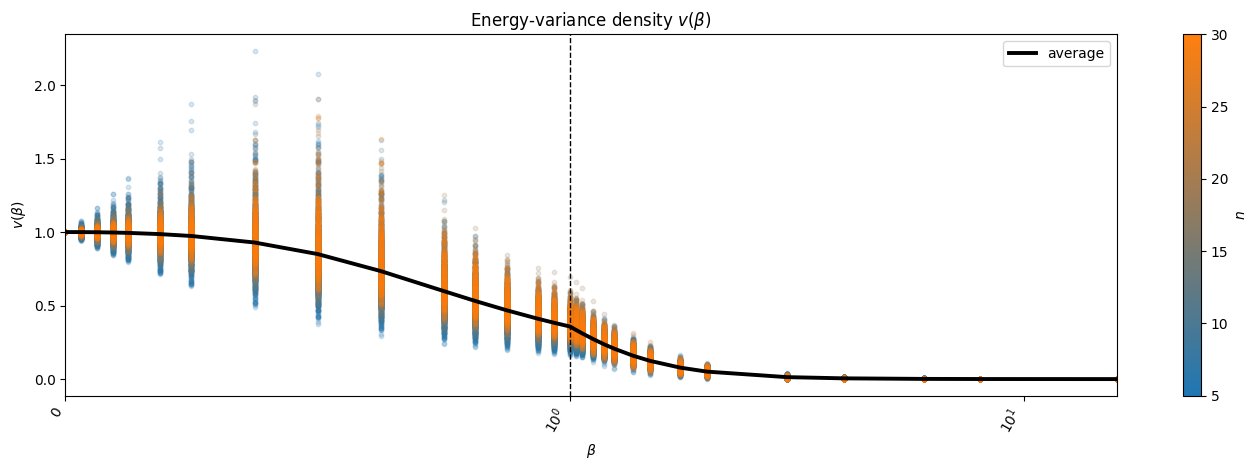

In [23]:
plt.close("all")
fig, ax = plt.subplots(figsize=(14, 4.8))

# This adds the single points beta -> v(beta) with color depending on n
for n, group in group_n:
    ax.scatter(group["beta"], group["v"], s=10, alpha=0.18, color=cmap(norm(n)))

# This add a line in black with the average variance among all instances of all n, by beta
mean_by_n_beta = group_n_beta["v"].mean()
mean_by_beta = mean_by_n_beta.groupby("beta", as_index=False)["v"].mean()
ax.plot(mean_by_beta["beta"], mean_by_beta["v"], color="black", linewidth=2.8, label="average")

# Set the axis metadata
beta_ticks = [0.0, 1.0 / 32.0, 1.0 / 16.0, 3.0 / 32.0, 1.0 / 8.0, 3.0 / 16.0, 1.0 / 4.0, 3.0 / 8.0, 1.0 / 2.0, 5.0 / 8.0, 3.0 / 4.0, 13.0 / 16.0, 7.0 / 8.0, 15.0 / 16.0, 1.0, 9.0 / 8.0, 5.0 / 4.0, 11.0 / 8.0, 3.0 / 2.0, 7.0 / 4.0, 2.0, 3.0, 4.0, 6.0, 8.0, 16.0]
beta_tick_labels = [r"$0$", r"$1/32$", r"$1/16$", r"$3/32$", r"$1/8$", r"$3/16$", r"$1/4$", r"$3/8$", r"$1/2$", r"$5/8$", r"$3/4$", r"$13/16$", r"$7/8$", r"$15/16$", r"$1$", r"$9/8$", r"$5/4$", r"$11/8$", r"$3/2$", r"$7/4$", r"$2$", r"$3$", r"$4$", r"$6$", r"$8$", r"$16$"]
ax.set_xticks(beta_ticks)
ax.set_xticklabels(beta_tick_labels, rotation=60, ha="right")
ax.set_xlim(0, 16)
ax.set_xlabel(r"$\beta$")
ax.set_ylabel(r"$v(\beta)$")
ax.set_xscale("symlog", linthresh=1.0)

# Add a vertical line separating high and low temperature
ax.axvline(1.0, color="black", linestyle="--", linewidth=1)

# Finalizing plot
ax.set_title(r"Energy-variance density $v(\beta)$")
ax.legend()
fig.colorbar(sm, ax=ax, label=r"$n$")
fig.tight_layout()

## Fitting the function $v(\beta)$

We propose an ansatz to describe $v(\beta)$. A possible choice here is the following function, which has been motivated by a trial-and-error process over several ansatzes:

$$v_{\mathrm{fit}}(\beta) =
\begin{cases} \exp\left[ \log(v_1)\beta + \kappa\beta(1-\beta) \right], & \beta<1, \\[2mm]
v_1 \left( 1+ \dfrac{\beta-1}{\tau} \right)^{-7/2}, & \beta\geq 1.
\end{cases}$$

To determine the values of $v_1,\kappa,\tau$, we perform a nonlinear least-squares fit in logarithmic space using the numerically estimated variances.

In [35]:
def variance_density_ansatz(parameters, beta):
    """Reduced piecewise variance-density ansatz."""
    log_v1, kappa, log_tau = parameters
    v1, tau = np.exp(log_v1), np.exp(log_tau)
    beta = np.asarray(beta, dtype=float)

    low = np.exp(log_v1 * beta + kappa * beta * (1.0 - beta))
    high = v1 * (1.0 + (beta - 1.0) / tau) ** -3.5
    return np.where(beta < 1.0, low, high)


def fit_variance_density(table):
    """Fit the ansatz in logarithmic space."""
    n = np.array(table["n"], dtype=float)
    beta = np.array(table["beta"], dtype=float)
    V = np.array(table["V"], dtype=float)

    def residual(parameters):
        return np.log(n * variance_density_ansatz(parameters, beta)) - np.log(V)

    initial = [np.log(0.36), 1.25, np.log(1.3)]
    return least_squares(residual, initial).x

agg = group_n_beta.agg(
    V=("var_energy", "mean"),
    V_std=("var_energy", "std"),
    count=("var_energy", "count"),
)
log_v1, kappa, log_tau = fit_variance_density(agg)

print(f"v1 = {np.exp(log_v1):.5f}")
print(f"kappa = {kappa:.5f}")
print(f"tau = {np.exp(log_tau):.5f}")

v1 = 0.37108
kappa = 1.21638
tau = 1.28274


For $v_1 = 0.37108, \kappa = 1.21638, \tau = 1.28274$ we have that:

$$v_{\mathrm{fit}}(\beta)=
\begin{cases}
\exp\left(0.22504\,\beta-1.21638\,\beta^2\right), & \beta<1,\\[2mm]
\left(0.29259+1.03483\,\beta\right)^{-7/2}, & \beta\geq1.
\end{cases}$$

This can be verified symbolically:

In [52]:
import sympy as sp

beta, n = sp.symbols("beta n", positive=True)
v1, kappa, tau = 0.37108, 1.21638, 1.28274

vfit_low = sp.exp(sp.expand(sp.log(v1) * beta + kappa * beta * (1 - beta)))

scale = v1 ** (-sp.Rational(2, 7))
vfit_high = sp.Pow(scale * (tau - 1) / tau + scale * beta / tau, sp.Rational(-7, 2), evaluate=False)

print(vfit_low)
print(vfit_high)

exp(-1.21638*beta**2 + 0.225042393802934*beta)
(1.03483386921505*beta + 0.292588928181864)**(-7/2)


Considering this ansatz fit the average behaviour, one might want to consider a more conservative choice. We consider therefore the following, which increases by a factor of $4$ and $16$ the high- and low-temperature branches respectively, 
$$v_{\mathrm{safe}}(\beta)=
\begin{cases}
4\times \exp\left(0.22504\,\beta-1.21638\,\beta^2\right), & \beta<1,\\[2mm]
16\times \left(0.29259+1.03483\,\beta\right)^{-7/2}, & \beta\geq1.
\end{cases}$$
which leads to 

$$
\Delta\beta(n,\beta)
=
\frac{2}{\sqrt{n\,v(\beta)}}
=
\frac{1}{\sqrt{n}}
\begin{cases}
\exp\left(-0.11252\,\beta+0.60819\,\beta^2\right), & \beta<1,\\[2mm]
0.53088\,(\beta+0.28274)^{7/4}, & \beta\geq1.
\end{cases}
$$

In [56]:
v_low = 4 * sp.exp(sp.log(v1) * beta + kappa * beta * (1 - beta))
v_high = 16 * v1 * (1 + (beta - 1) / tau) ** sp.Rational(-7, 2)

delta_low = 2 / sp.sqrt(n * v_low)
delta_high = 2 / sp.sqrt(n * v_high)

# Rewrite in the desired form.
print(sp.expand_mul(sp.simplify(delta_low)))
print(sp.factor(delta_high))

exp(0.60819*beta**2 - 0.112521196901467*beta)/sqrt(n)
0.530876638566998*(1.0*beta + 0.28274)**(7/4)/sqrt(n)


## Validation of the annealing safety factors

We have introduced factors of $4$ and $16$ in the two branches of $v(\beta)$ to obtain a more conservative annealing schedule. We now verify empirically that these factors are sufficient for the ensemble of instances considered.

First, we generate a valid annealing schedule up to $\bar\beta=16$ for every instance. The step size is chosen as
$$
\Delta\beta(n,\beta)=\frac{2}{\sqrt{s\,n\,v(\beta)}},
$$
where $s\geq1$ is a safety factor.

The resulting schedules are stored in the `schedule_outputs` folder. Each file corresponds to a single instance and contains a sequence of tuples $(\beta,\chi,s)$, where $\beta$ is the current inverse temperature, $\chi$ is the squared overlap between the Gibbs states at $\beta$ and $\beta+\Delta\beta$, and $s$ is the safety factor used to determine the step size.

The schedule is generated adaptively. Each step is first attempted with $s=1$. If the resulting overlap violates the required condition $\chi\geq 1/e$, the safety factor is increased until the condition is satisfied. The script `collect_schedule.py` summarizes these results in a Pickle file, with one row for each pair $(n,\mathrm{idx})$.

We can therefore determine, for each system size, the largest safety factor required by any instance. In particular, the maximum value of $s$ observed over the whole ensemble provides a direct indication of how much the fitted variance density must be increased to ensure that the overlap condition is satisfied along these adaptively generated schedules.

In [66]:
df = pd.read_pickle("../estimation_variance/schedule_summary.pkl")

summary = df.groupby("n").agg({
    "L": ["mean", "std"],
    "overlap_min": ["mean", "std", "min"],
    "overlap_num_invalid": ["mean", "max"],
    "S_max": ["mean", "std", "max"],
    "S_num_invalid": ["mean", "max"],
})

summary

L           overlap_min                     overlap_num_invalid      \
    mean       std        mean       std       min                mean max   
n                                                                            
5   5.00  0.000000    0.476229  0.070262  0.367931                 0.0   0   
6   5.00  0.000000    0.454887  0.064491  0.367948                 0.0   0   
7   5.00  0.000000    0.450994  0.055436  0.367982                 0.0   0   
8   5.00  0.000000    0.429553  0.045386  0.371236                 0.0   0   
9   5.00  0.000000    0.420745  0.039320  0.368340                 0.0   0   
10  5.00  0.000000    0.419110  0.037907  0.368418                 0.0   0   
11  6.00  0.000000    0.412752  0.033016  0.368484                 0.0   0   
12  6.00  0.000000    0.411523  0.032749  0.368163                 0.0   0   
13  6.00  0.000000    0.404254  0.023091  0.368892                 0.0   0   
14  6.00  0.000000    0.400474  0.022258  0.368068                 0.0   0   
15  6.02  0.140705    0.400451  0.023111  0.368013                 0.0   0   
16  6.09  0.287623    0.395644  0.018666  0.369539                 0.0   0   
17  6.32  0.468826    0.394542  0.019479  0.368117                 0.0   0   
18  7.00  0.000000    0.391880  0.016400  0.367908                 0.0   0   
19  7.00  0.000000    0.388663  0.014160  0.368144                 0.0   0   
20  7.00  0.000000    0.391973  0.015811  0.368699                 0.0   0   
21  7.00  0.000000    0.389576  0.015075  0.368075                 0.0   0   
22  7.00  0.000000    0.388382  0.013700  0.368240                 0.0   0   
23  7.00  0.000000    0.388687  0.013606  0.367909                 0.0   0   
24  7.00  0.000000    0.387010  0.012452  0.368506                 0.0   0   
25  7.00  0.000000    0.386478  0.011011  0.368311                 0.0   0   
26  7.00  0.000000    0.384826  0.010787  0.367935                 0.0   0   
27  7.00  0.000000    0.384062  0.010629  0.368093                 0.0   0   
28  8.00  0.000000    0.386489  0.009478  0.368624                 0.0   0   
29  8.00  0.000000    0.383600  0.010860  0.367937                 0.0   0   
30  8.00  0.000000    0.381726  0.009762  0.368008                 0.0   0   

    S_max                S_num_invalid      
     mean       std  max          mean max  
n                                           
5   1.035  0.099874  1.5          0.14   1  
6   1.056  0.154606  2.0          0.19   1  
7   1.038  0.113511  1.7          0.13   1  
8   1.061  0.127045  1.6          0.25   1  
9   1.052  0.112349  1.6          0.25   1  
10  1.046  0.089239  1.5          0.28   1  
11  1.049  0.101000  1.5          0.27   1  
12  1.049  0.087033  1.4          0.31   1  
13  1.049  0.094810  1.5          0.29   1  
14  1.041  0.077973  1.4          0.29   1  
15  1.044  0.076963  1.4          0.33   2  
16  1.047  0.083430  1.4          0.37   2  
17  1.052  0.096901  1.6          0.38   2  
18  1.054  0.105811  1.6          0.39   2  
19  1.046  0.080929  1.5          0.40   2  
20  1.052  0.098964  1.6          0.46   2  
21  1.062  0.101285  1.6          0.61   2  
22  1.063  0.139736  1.9          0.46   2  
23  1.046  0.068785  1.3          0.48   2  
24  1.045  0.074366  1.4          0.48   2  
25  1.067  0.089955  1.5          0.74   2  
26  1.052  0.096901  1.6          0.50   2  
27  1.062  0.126953  1.9          0.51   2  
28  1.084  0.146832  1.9          0.73   2  
29  1.074  0.093873  1.5          0.79   2  
30  1.064  0.105906  1.6          0.62   2

A factor of $2$ is already sufficient for the adaptive schedule to give a schedule satisying the desired properties. 

Since in practice we cannot access the overlap between distribution thus the adaptive schedule is not implementable, one could check if simply setting the safety value $2$ in a non-adaptive schedule actually creates any violation of the condition and how big is such violation.

This shows that even with a non-adaptive schedule, with the generated instances this is enough. 

In [67]:
df = pd.read_pickle("../estimation_variance/schedule_summary_safe.pkl") 

summary = df.groupby("n").agg({
    "L": ["mean", "std"],
    "overlap_min": ["mean", "std", "min"],
    "overlap_num_invalid": ["mean", "max"],
    "S_max": ["mean", "std", "max"],
    "S_num_invalid": ["mean", "max"],
})

summary

L      overlap_min                     overlap_num_invalid     S_max  \
    mean  std        mean       std       min                mean max  mean   
n                                                                             
5    5.0  0.0    0.644787  0.059197  0.479737                 0.0   0   2.0   
6    6.0  0.0    0.631177  0.064147  0.386512                 0.0   0   2.0   
7    6.0  0.0    0.633849  0.052553  0.429535                 0.0   0   2.0   
8    6.0  0.0    0.619260  0.046840  0.479910                 0.0   0   2.0   
9    7.0  0.0    0.617937  0.042586  0.473355                 0.0   0   2.0   
10   7.0  0.0    0.617192  0.038969  0.494791                 0.0   0   2.0   
11   7.0  0.0    0.613527  0.040462  0.446611                 0.0   0   2.0   
12   7.0  0.0    0.614603  0.034670  0.506126                 0.0   0   2.0   
13   7.0  0.0    0.608150  0.037765  0.439396                 0.0   0   2.0   
14   8.0  0.0    0.609214  0.029964  0.479440                 0.0   0   2.0   
15   8.0  0.0    0.607839  0.034973  0.450413                 0.0   0   2.0   
16   8.0  0.0    0.604681  0.032175  0.432217                 0.0   0   2.0   
17   8.0  0.0    0.603495  0.037159  0.390170                 0.0   0   2.0   
18   8.0  0.0    0.601373  0.037804  0.465944                 0.0   0   2.0   
19   8.0  0.0    0.604512  0.024404  0.487151                 0.0   0   2.0   
20   8.0  0.0    0.604613  0.027715  0.485232                 0.0   0   2.0   
21   9.0  0.0    0.599191  0.030927  0.471909                 0.0   0   2.0   
22   9.0  0.0    0.600169  0.035598  0.406850                 0.0   0   2.0   
23   9.0  0.0    0.604696  0.021677  0.508482                 0.0   0   2.0   
24   9.0  0.0    0.603343  0.023691  0.501037                 0.0   0   2.0   
25   9.0  0.0    0.598253  0.026207  0.465858                 0.0   0   2.0   
26   9.0  0.0    0.599703  0.028646  0.473292                 0.0   0   2.0   
27  10.0  0.0    0.600304  0.028801  0.444910                 0.0   0   2.0   
28  10.0  0.0    0.595524  0.033144  0.435707                 0.0   0   2.0   
29  10.0  0.0    0.594697  0.026878  0.486909                 0.0   0   2.0   
30  10.0  0.0    0.596167  0.029522  0.465195                 0.0   0   2.0   

             S_num_invalid      
    std  max          mean max  
n                               
5   0.0  2.0           5.0   5  
6   0.0  2.0           6.0   6  
7   0.0  2.0           6.0   6  
8   0.0  2.0           6.0   6  
9   0.0  2.0           7.0   7  
10  0.0  2.0           7.0   7  
11  0.0  2.0           7.0   7  
12  0.0  2.0           7.0   7  
13  0.0  2.0           7.0   7  
14  0.0  2.0           8.0   8  
15  0.0  2.0           8.0   8  
16  0.0  2.0           8.0   8  
17  0.0  2.0           8.0   8  
18  0.0  2.0           8.0   8  
19  0.0  2.0           8.0   8  
20  0.0  2.0           8.0   8  
21  0.0  2.0           9.0   9  
22  0.0  2.0           9.0   9  
23  0.0  2.0           9.0   9  
24  0.0  2.0           9.0   9  
25  0.0  2.0           9.0   9  
26  0.0  2.0           9.0   9  
27  0.0  2.0          10.0  10  
28  0.0  2.0          10.0  10  
29  0.0  2.0          10.0  10  
30  0.0  2.0          10.0  10

Clearly the same holds even for the conservative choice, which has even shorter steps. 

In [69]:
df = pd.read_pickle("../estimation_variance/schedule_summary_conservative.pkl") 

summary = df.groupby("n").agg({
    "L": ["mean", "std"],
    "overlap_min": ["mean", "std", "min"],
    "overlap_num_invalid": ["mean", "max"],
})

summary

L      overlap_min                     overlap_num_invalid    
    mean  std        mean       std       min                mean max
n                                                                    
5    9.0  0.0    0.789848  0.031142  0.706208                 0.0   0
6   10.0  0.0    0.783631  0.035406  0.656785                 0.0   0
7   10.0  0.0    0.786075  0.028369  0.677743                 0.0   0
8   10.0  0.0    0.777670  0.030775  0.653421                 0.0   0
9   11.0  0.0    0.778321  0.028935  0.639782                 0.0   0
10  11.0  0.0    0.777456  0.026530  0.665557                 0.0   0
11  12.0  0.0    0.775760  0.029415  0.655111                 0.0   0
12  13.0  0.0    0.777288  0.023449  0.681754                 0.0   0
13  13.0  0.0    0.773037  0.028417  0.613272                 0.0   0
14  13.0  0.0    0.774580  0.021846  0.678815                 0.0   0
15  13.0  0.0    0.774596  0.022802  0.665073                 0.0   0
16  13.0  0.0    0.772823  0.022140  0.663235                 0.0   0
17  14.0  0.0    0.771429  0.026423  0.627128                 0.0   0
18  14.0  0.0    0.769937  0.027297  0.659465                 0.0   0
19  15.0  0.0    0.773204  0.019455  0.678449                 0.0   0
20  15.0  0.0    0.771916  0.022834  0.665276                 0.0   0
21  16.0  0.0    0.768254  0.024146  0.660016                 0.0   0
22  16.0  0.0    0.769585  0.028674  0.616696                 0.0   0
23  16.0  0.0    0.773034  0.016981  0.700379                 0.0   0
24  16.0  0.0    0.772212  0.019124  0.687870                 0.0   0
25  16.0  0.0    0.767988  0.021377  0.672908                 0.0   0
26  16.0  0.0    0.769552  0.022831  0.663242                 0.0   0
27  17.0  0.0    0.769354  0.025095  0.621081                 0.0   0
28  17.0  0.0    0.765697  0.028426  0.626676                 0.0   0
29  17.0  0.0    0.766238  0.021143  0.682838                 0.0   0
30  17.0  0.0    0.767036  0.023701  0.666113                 0.0   0